In [1]:
import os
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

In [2]:
pth = os.path.join('..', '..')
pth_data = os.path.join(pth, 'data')
pth_in = os.path.join(pth_data, 'development', 'modeling')
pth_feat = os.path.join(pth_data, 'features', 'biomart')
pth_out = os.path.join(pth, 'figures', 'mesencoder', 'competition')

In [3]:
adata = sc.read_h5ad(os.path.join(pth_in, 'bifurcation.h5ad'))
adata

AnnData object with n_obs × n_vars = 6405 × 510
    obs: 'sample', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'leiden', 'celltype', 'total_counts_ribo', 'pct_counts_ribo', 'T+ Sox2+', 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'RNA_snn_res.0.1', 'seurat_clusters', 'age', 'RNA_snn_res.0.5', 'ident', 'velocity_self_transition', 'celltype_original', 'source', 'GSE162534', 'GSE229103', 'rRNAModifications', 't_orig', 'early', 'late', 'spectrum', 't', 'seg', 'edge', 'milestones'
    uns: 'celltype_colors', 'graph', 'milestones_colors', 'pseudotime_list', 'seg_colors'
    obsm: 'X_R', 'X_mesencoder', 'X_pca', 'X_pca_harmony', 'X_spectrum', 'X_umap', 'X_umap_traj', 'velocity_umap'
    layers: 'logcounts', 'scaled'

In [4]:
# select: Branch1 (cells), Mes1+2 (genes)
mod_early = ('GSE162534', 'GSE229103')
get_pth = lambda src: os.path.join(pth_feat, f'{src}.csv')
get_feat = lambda pth: pd.read_csv(pth).mmusculus.values
g = np.union1d(*[get_feat(get_pth(src)) for src in mod_early])
adata1 = adata[(adata.obs.source == 'GSE162534'), g].copy()
adata1

AnnData object with n_obs × n_vars = 2811 × 338
    obs: 'sample', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'leiden', 'celltype', 'total_counts_ribo', 'pct_counts_ribo', 'T+ Sox2+', 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'RNA_snn_res.0.1', 'seurat_clusters', 'age', 'RNA_snn_res.0.5', 'ident', 'velocity_self_transition', 'celltype_original', 'source', 'GSE162534', 'GSE229103', 'rRNAModifications', 't_orig', 'early', 'late', 'spectrum', 't', 'seg', 'edge', 'milestones'
    uns: 'celltype_colors', 'graph', 'milestones_colors', 'pseudotime_list', 'seg_colors'
    obsm: 'X_R', 'X_mesencoder', 'X_pca', 'X_pca_harmony', 'X_spectrum', 'X_umap', 'X_umap_traj', 'velocity_umap'
    layers: 'logcounts', 'scaled'

In [5]:
# compute neighbors & pseudotime windows
sc.pp.neighbors(adata1, 200, use_rep = 'X_mesencoder')
adata1.obs['t_bin'] = pd.cut(adata1.obs.t_orig, 7)

# mutual negative correlation (windowed)
r_dict = dict()
for bin, sdf in adata1.obs.groupby('t_bin', observed = True):
    adata_bin = adata1[sdf.index].copy()
    X = pd.DataFrame(adata_bin.X.toarray(),
                     index = sdf.index,
                     columns = adata1.var_names)
    X = X.loc[:, (X.nunique(axis = 0) > 1)].copy()
    mod1 = sdf[mod_early[0]].values[:, None]
    mod2 = sdf[mod_early[1]].values[:, None]
    a = pearsonr(X, mod1, axis = 0).statistic
    b = pearsonr(X, mod2, axis = 0).statistic
    r_dict[bin] = -np.corrcoef(a, b)[0, 1]

# smoothing (neighbors)
A = adata1.obsp['connectivities']
R = adata1.obs.t_bin.map(r_dict)
R_sm = (A @ R) / A.sum(axis = 1).A1
adata1.obs['competition'] = R_sm

In [6]:
del adata1.obs['t_bin']
adata1.write(os.path.join(pth_in, 'competition.h5ad'))
adata1

AnnData object with n_obs × n_vars = 2811 × 338
    obs: 'sample', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'leiden', 'celltype', 'total_counts_ribo', 'pct_counts_ribo', 'T+ Sox2+', 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'RNA_snn_res.0.1', 'seurat_clusters', 'age', 'RNA_snn_res.0.5', 'ident', 'velocity_self_transition', 'celltype_original', 'source', 'GSE162534', 'GSE229103', 'rRNAModifications', 't_orig', 'early', 'late', 'spectrum', 't', 'seg', 'edge', 'milestones', 'competition'
    uns: 'celltype_colors', 'graph', 'milestones_colors', 'pseudotime_list', 'seg_colors', 'neighbors'
    obsm: 'X_R', 'X_mesencoder', 'X_pca', 'X_pca_harmony', 'X_spectrum', 'X_umap', 'X_umap_traj', 'velocity_umap'
    layers: 'logcounts', 'scaled'
    obsp: 'distances', 'connectivities'

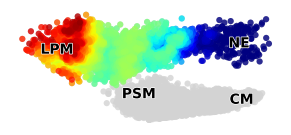

In [7]:
# plot module competition
fig, ax = plt.subplots(1, 1, figsize = (3.5, 1.5))
sc.pl.embedding(adata, 'X_mesencoder', dimensions = [1, 0],
                size = 80, alpha = .8, frameon = False,
                show = False, ax = ax)
sc.pl.embedding(adata1, 'X_mesencoder', dimensions = [1, 0],
                size = 80, alpha = .8, color = 'competition',
                cmap = 'jet', colorbar_loc = None,
                frameon = False, show = False, ax = ax)
sc.pl.embedding(adata, 'X_mesencoder', dimensions = [1, 0],
                size = 80, alpha = 0, color = 'celltype',
                legend_loc = 'on data', legend_fontoutline = 1,
                frameon = False, show = False, ax = ax)
ax.set_title(''); ax.invert_yaxis()

label_dict = {
    'Cranial Mesenchyme'         : 'CM',
    'Lateral Plate Mesoderm'     : 'LPM',
    'Migratory Neural Crest'     : '',
    'nan'                        : '',
    'Nascent Endothelium'        : 'NE',
    'Neuroglial Progenitors'     : '',
    'Neuromesodermal Progenitor' : '',
    'Premigratory Neural Crest'  : '',
    'Presomitic Mesoderm'        : 'PSM',
    'Somite'                     : ''}

pos_dict = {
    'Cranial Mesenchyme'     : (.1, 0),
    'Lateral Plate Mesoderm' : (-.925, .05),
    'Nascent Endothelium'    : (.75, .05),
    'Presomitic Mesoderm'    : (-.265, -.175)}

for label in ax.texts:
    _label_ = label.get_text()
    x, y = label.get_position()
    if _label_ in label_dict:
        label.set_text(label_dict[_label_])
    if _label_ in pos_dict:
        dx, dy = pos_dict[_label_]
        label.set_position([x + dx, y + dy])

fn = os.path.join(pth_out, 'correlation.pdf')
plt.savefig(fn, bbox_inches = 'tight')

/tmp/ipykernel_3467236/3211195324.py:3: UserWarning: Adding colorbar to a different Figure <Figure size 350x150 with 1 Axes> than <Figure size 66x100 with 1 Axes> which fig.colorbar is called on.
  cb = plt.colorbar(ax.collections[1], cax = cax)


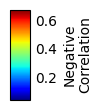

In [8]:
fig = plt.figure(figsize = (.66, 1))
cax = fig.add_axes([.35, .05, .3, .9])
cb = plt.colorbar(ax.collections[1], cax = cax)
cb.ax.tick_params(which = 'both', size = 0)
cb.set_label('Negative\nCorrelation')
cb.set_ticks([.2, .4, .6])
cb.solids.set_alpha(1)
fn = os.path.join(pth_out, 'correlation_cb.pdf')
plt.savefig(fn, bbox_inches = 'tight')

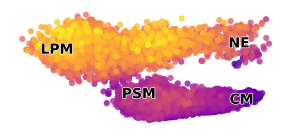

In [9]:
mod = 'GSE162534'

fig, ax = plt.subplots(1, 1, figsize = (3.5, 1.5))
sc.pl.embedding(adata, 'X_mesencoder', dimensions = [1, 0],
                size = 80, alpha = .8, color = mod,
                cmap = 'plasma', colorbar_loc = None,
                frameon = False, show = False, ax = ax)
sc.pl.embedding(adata, 'X_mesencoder', dimensions = [1, 0],
                size = 80, alpha = 0, color = 'celltype',
                legend_loc = 'on data', legend_fontoutline = 1,
                frameon = False, show = False, ax = ax)
ax.set_title(''); ax.invert_yaxis()

label_dict = {
    'Cranial Mesenchyme'         : 'CM',
    'Lateral Plate Mesoderm'     : 'LPM',
    'Migratory Neural Crest'     : '',
    'nan'                        : '',
    'Nascent Endothelium'        : 'NE',
    'Neuroglial Progenitors'     : '',
    'Neuromesodermal Progenitor' : '',
    'Premigratory Neural Crest'  : '',
    'Presomitic Mesoderm'        : 'PSM',
    'Somite'                     : ''}

pos_dict = {
    'Cranial Mesenchyme'     : (.1, 0),
    'Lateral Plate Mesoderm' : (-.925, .05),
    'Nascent Endothelium'    : (.75, .05),
    'Presomitic Mesoderm'    : (-.265, -.175)}

for label in ax.texts:
    _label_ = label.get_text()
    x, y = label.get_position()
    if _label_ in label_dict:
        label.set_text(label_dict[_label_])
    if _label_ in pos_dict:
        dx, dy = pos_dict[_label_]
        label.set_position([x + dx, y + dy])

fn = os.path.join(pth_out, f'{mod}.pdf')
plt.savefig(fn, bbox_inches = 'tight')

/tmp/ipykernel_3467236/2850612242.py:3: UserWarning: Adding colorbar to a different Figure <Figure size 350x150 with 1 Axes> than <Figure size 66x100 with 1 Axes> which fig.colorbar is called on.
  cb = plt.colorbar(ax.collections[0], cax = cax)


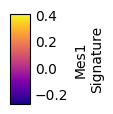

In [10]:
fig = plt.figure(figsize = (.66, 1))
cax = fig.add_axes([.35, .05, .3, .9])
cb = plt.colorbar(ax.collections[0], cax = cax)
cb.ax.tick_params(which = 'both', size = 0)
cb.set_label('Mes1\nSignature')
cb.set_ticks([-.2, 0, .2, .4])
cb.solids.set_alpha(1)
fn = os.path.join(pth_out, f'{mod}_cb.pdf')
plt.savefig(fn, bbox_inches = 'tight')

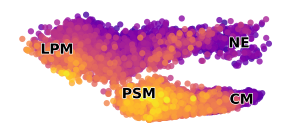

In [11]:
mod = 'GSE229103'

fig, ax = plt.subplots(1, 1, figsize = (3.5, 1.5))
sc.pl.embedding(adata, 'X_mesencoder', dimensions = [1, 0],
                size = 80, alpha = .8, color = mod,
                cmap = 'plasma', colorbar_loc = None,
                frameon = False, show = False, ax = ax)
sc.pl.embedding(adata, 'X_mesencoder', dimensions = [1, 0],
                size = 80, alpha = 0, color = 'celltype',
                legend_loc = 'on data', legend_fontoutline = 1,
                frameon = False, show = False, ax = ax)
ax.set_title(''); ax.invert_yaxis()

label_dict = {
    'Cranial Mesenchyme'         : 'CM',
    'Lateral Plate Mesoderm'     : 'LPM',
    'Migratory Neural Crest'     : '',
    'nan'                        : '',
    'Nascent Endothelium'        : 'NE',
    'Neuroglial Progenitors'     : '',
    'Neuromesodermal Progenitor' : '',
    'Premigratory Neural Crest'  : '',
    'Presomitic Mesoderm'        : 'PSM',
    'Somite'                     : ''}

pos_dict = {
    'Cranial Mesenchyme'     : (.1, 0),
    'Lateral Plate Mesoderm' : (-.925, .05),
    'Nascent Endothelium'    : (.75, .05),
    'Presomitic Mesoderm'    : (-.265, -.175)}

for label in ax.texts:
    _label_ = label.get_text()
    x, y = label.get_position()
    if _label_ in label_dict:
        label.set_text(label_dict[_label_])
    if _label_ in pos_dict:
        dx, dy = pos_dict[_label_]
        label.set_position([x + dx, y + dy])

fn = os.path.join(pth_out, f'{mod}.pdf')
plt.savefig(fn, bbox_inches = 'tight')

/tmp/ipykernel_3467236/612517380.py:3: UserWarning: Adding colorbar to a different Figure <Figure size 350x150 with 1 Axes> than <Figure size 66x100 with 1 Axes> which fig.colorbar is called on.
  cb = plt.colorbar(ax.collections[0], cax = cax)


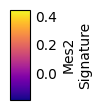

In [12]:
fig = plt.figure(figsize = (.66, 1))
cax = fig.add_axes([.35, .05, .3, .9])
cb = plt.colorbar(ax.collections[0], cax = cax)
cb.ax.tick_params(which = 'both', size = 0)
cb.set_label('Mes2\nSignature')
cb.set_ticks([0, .2, .4])
cb.solids.set_alpha(1)
fn = os.path.join(pth_out, f'{mod}_cb.pdf')
plt.savefig(fn, bbox_inches = 'tight')